In [102]:
import pandas as pd

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

BASE = 'datas'
portscan = pd.read_csv(f'{BASE}/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv')
DDoS = pd.read_csv(f'{BASE}/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')
DoS = pd.read_csv(f'{BASE}/wednesday-workingHours.pcap_ISCX.csv')
webAttack = pd.read_csv(f'{BASE}/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv')


### TRATAR OS DADOS DO DATAFRAME PORTSCAN

In [103]:
print(f"\n===== PortScan =====")
print("Shape:", portscan.shape)
print("\nTipos:")
print(portscan.dtypes)


===== PortScan =====
Shape: (286467, 79)

Tipos:
 Destination Port                 int64
 Flow Duration                    int64
 Total Fwd Packets                int64
 Total Backward Packets           int64
Total Length of Fwd Packets       int64
 Total Length of Bwd Packets      int64
 Fwd Packet Length Max            int64
 Fwd Packet Length Min            int64
 Fwd Packet Length Mean         float64
 Fwd Packet Length Std          float64
Bwd Packet Length Max             int64
 Bwd Packet Length Min            int64
 Bwd Packet Length Mean         float64
 Bwd Packet Length Std          float64
Flow Bytes/s                    float64
 Flow Packets/s                 float64
 Flow IAT Mean                  float64
 Flow IAT Std                   float64
 Flow IAT Max                     int64
 Flow IAT Min                     int64
Fwd IAT Total                     int64
 Fwd IAT Mean                   float64
 Fwd IAT Std                    float64
 Fwd IAT Max                  

In [104]:
print("\nValores ausentes:")
print(portscan.isna().sum())

## precisamos tratar os valores ausentes da coluna 'Flow Bytes/s' para o portscan, pois é uma feature importante para a detecção de intrusões. Vamos verificar quais linhas possuem valores ausentes nessa coluna.


Valores ausentes:
 Destination Port                0
 Flow Duration                   0
 Total Fwd Packets               0
 Total Backward Packets          0
Total Length of Fwd Packets      0
 Total Length of Bwd Packets     0
 Fwd Packet Length Max           0
 Fwd Packet Length Min           0
 Fwd Packet Length Mean          0
 Fwd Packet Length Std           0
Bwd Packet Length Max            0
 Bwd Packet Length Min           0
 Bwd Packet Length Mean          0
 Bwd Packet Length Std           0
Flow Bytes/s                    15
 Flow Packets/s                  0
 Flow IAT Mean                   0
 Flow IAT Std                    0
 Flow IAT Max                    0
 Flow IAT Min                    0
Fwd IAT Total                    0
 Fwd IAT Mean                    0
 Fwd IAT Std                     0
 Fwd IAT Max                     0
 Fwd IAT Min                     0
Bwd IAT Total                    0
 Bwd IAT Mean                    0
 Bwd IAT Std                     0
 

In [105]:
filtro_nulos = portscan['Flow Bytes/s'].isna()
portscan_nulos = portscan[filtro_nulos]
portscan_nulos

## iremos remover as linhas com valores ausentes na coluna 'Flow Bytes/s' para o portscan, pois são poucas.

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
12824,13370,0,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,64,0,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,1,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,65535,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
12827,52508,0,1,1,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,32,32,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,1,0.0,0.0,0.0,32,0,0,0,0,0,0,1,0,1,0,227,65535,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
14192,46058,0,1,1,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,32,32,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,1,0.0,0.0,0.0,32,0,0,0,0,0,0,1,0,1,0,227,229,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
40707,57119,0,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,64,0,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,1,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,65535,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
52456,16506,0,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,64,0,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,229,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
56603,52995,0,1,1,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,44,32,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,1,0.0,0.0,0.0,44,0,0,0,0,0,0,1,0,1,0,408,65535,0,44,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
76549,48337,0,1,1,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,32,32,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,1,0.0,0.0,0.0,32,0,0,0,0,0,0,1,0,1,0,227,229,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
76773,38790,0,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,64,0,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,126,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225846,36648,0,1,1,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,32,32,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,1,0.0,0.0,0.0,32,0,0,0,0,0,0,1,0,1,0,5438,38864,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
237968,51204,0,2,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,NaN,inf,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,64,0,0.0,0.0,0,0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0,0.0,0.0,0.0,64,0,0,0,0,0,0,2,0,0,0,357,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [106]:
portscan.dropna(subset=['Flow Bytes/s'], inplace=True)

portscan['Flow Bytes/s'].isna().sum()

np.int64(0)

In [107]:
import numpy as np

# Seleciona apenas colunas numéricas (float e int)
portscan_num = portscan.select_dtypes(include=[np.number])

# Agora sim, verifica os infinitos
contagem_inf = np.isinf(portscan_num).sum()

# Mostra apenas as colunas que têm pelo menos um 'inf'
print(contagem_inf[contagem_inf > 0])

Flow Bytes/s       356
 Flow Packets/s    356
dtype: int64


In [108]:
import numpy as np

# Criar uma máscara para identificar onde estão os infinitos (apenas colunas numéricas)
df_num = portscan.select_dtypes(include=[np.number])
mask_inf = np.isinf(df_num).any(axis=1)

# Ver a contagem de Labels para as linhas que têm infinito
contagem_inf_por_classe = portscan[mask_inf][' Label'].value_counts()

print("Distribuição de valores 'inf' por classe:")
print(contagem_inf_por_classe)

Distribuição de valores 'inf' por classe:
 Label
BENIGN      230
PortScan    126
Name: count, dtype: int64


In [109]:
# Limpar espaços em branco nos nomes das colunas e nos valores da Label (prevenção)
portscan.columns = portscan.columns.str.strip()
portscan['Label'] = portscan['Label'].str.strip()

# Contagem absoluta e percentual
contagem = portscan['Label'].value_counts()
percentual = portscan['Label'].value_counts(normalize=True) * 100

print("Distribuição das Classes:")
print(pd.concat([contagem, percentual], axis=1, keys=['Total', '%']))

Distribuição das Classes:
           Total          %
Label                      
PortScan  158930  55.482245
BENIGN    127522  44.517755


In [110]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
portscan['Label'] = le.fit_transform(portscan['Label'])

print("Mapeamento realizado:", dict(zip(le.classes_, le.transform(le.classes_))))

Mapeamento realizado: {'BENIGN': np.int64(0), 'PortScan': np.int64(1)}


In [111]:
# 1. Converter infinitos em NaN
portscan.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2. Excluir todas as linhas que possuam QUALQUER valor NaN
portscan.dropna(inplace=True)

# 3. Resetar o índice (importante para não haver saltos na numeração das linhas)
portscan.reset_index(drop=True, inplace=True)

print(f"Dataset limpo! Novo formato: {portscan.shape}")

Dataset limpo! Novo formato: (286096, 79)


In [112]:
## Vamos verificar os dados duplicados para o portscan, pois podem afetar a performance do modelo.

portscan.duplicated().sum()

np.int64(72319)

In [113]:
## Verificamos que temos 72353 linhas duplicadas no portscan, o que é um número significativo. Vamos remover essas linhas duplicadas para melhorar a qualidade dos dados.
portscan.drop_duplicates(inplace=True)
print(f"Total de linhas agora: {len(portscan)}")

Total de linhas agora: 213777


In [114]:
# Identificar colunas onde todos os valores são iguais
colunas_constantes = [col for col in portscan.columns if portscan[col].nunique() <= 1]
print(f"Removendo {len(colunas_constantes)} colunas constantes: {colunas_constantes}")

# Remover do DataFrame
portscan.drop(columns=colunas_constantes, inplace=True)

Removendo 10 colunas constantes: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [115]:
portscan.info()

<class 'pandas.DataFrame'>
Index: 213777 entries, 0 to 286095
Data columns (total 69 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             213777 non-null  int64  
 1   Flow Duration                213777 non-null  int64  
 2   Total Fwd Packets            213777 non-null  int64  
 3   Total Backward Packets       213777 non-null  int64  
 4   Total Length of Fwd Packets  213777 non-null  int64  
 5   Total Length of Bwd Packets  213777 non-null  int64  
 6   Fwd Packet Length Max        213777 non-null  int64  
 7   Fwd Packet Length Min        213777 non-null  int64  
 8   Fwd Packet Length Mean       213777 non-null  float64
 9   Fwd Packet Length Std        213777 non-null  float64
 10  Bwd Packet Length Max        213777 non-null  int64  
 11  Bwd Packet Length Min        213777 non-null  int64  
 12  Bwd Packet Length Mean       213777 non-null  float64
 13  Bwd Packet Leng

In [116]:
features_para_escalonar = portscan.select_dtypes(include=['float64', 'int64']).columns.tolist()

In [117]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

# 1. Separar X (features) e y (target)
X = portscan.drop(columns=['Label'])
y = portscan['Label']

# 2. Dividir em Treino e Teste (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 3. Aplicar o Escalonador
scaler = RobustScaler()

# Ajusta no treino E transforma o treino
X_train_scaled = scaler.fit_transform(X_train)

# APENAS transforma o teste (usa os parâmetros do treino)
X_test_scaled = scaler.transform(X_test)

## Começar o treinamento dos modelos

## Decision Tree:

In [118]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# 1. Instanciar o modelo
# Usamos max_depth para a árvore não crescer demais e podermos visualizá-la
modelo_tree = DecisionTreeClassifier(max_depth=3, random_state=42)

# 2. Treinar
modelo_tree.fit(X_train_scaled, y_train)

# 3. Avaliar
y_pred_tree = modelo_tree.predict(X_test_scaled)

print("Acurácia da Árvore Simples:", accuracy_score(y_test, y_pred_tree))

Acurácia da Árvore Simples: 0.9960473383852558


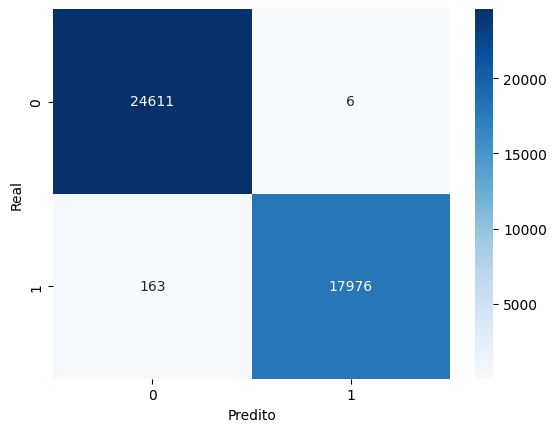

In [119]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_tree)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.show()

C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_17004\1084329885.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Atributo', data=df_importancia, palette='magma')


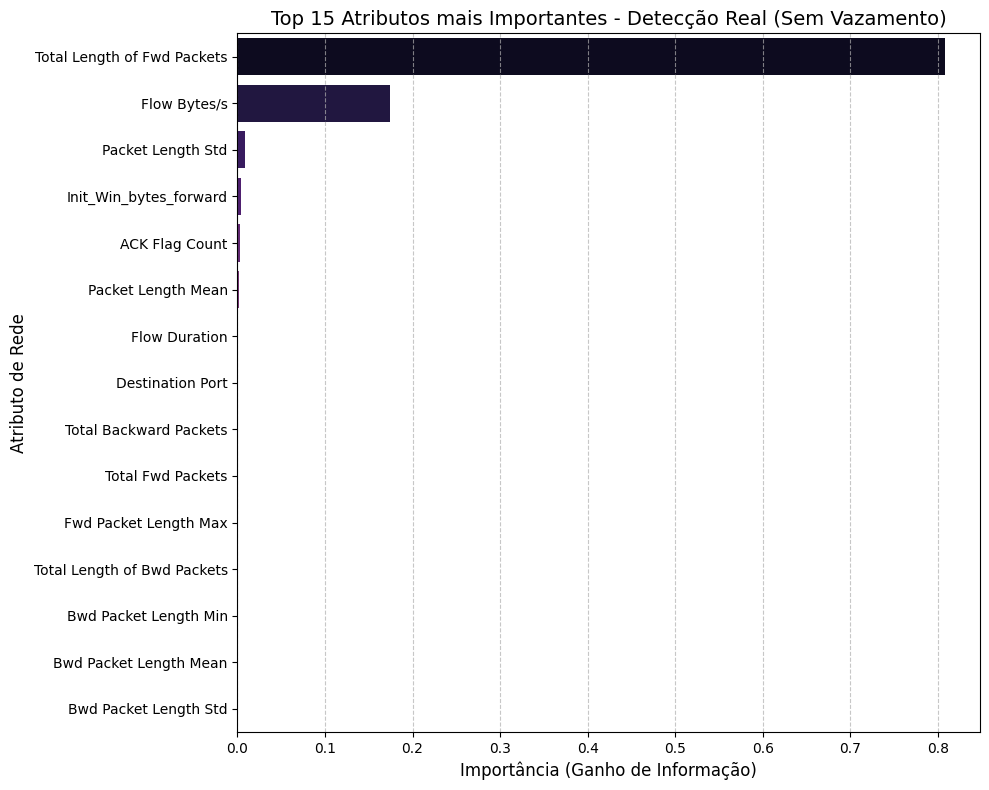

In [121]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extrair as importâncias do modelo
importancias = modelo_tree.feature_importances_

# 2. Pegar os nomes das colunas DIRETO do X que você usou no split
# Isso garante que o tamanho seja exatamente o mesmo
colunas = X.columns 

# 3. Criar o DataFrame (agora com tamanhos iguais)
df_importancia = pd.DataFrame({'Atributo': colunas, 'Importancia': importancias})
df_importancia = df_importancia.sort_values(by='Importancia', ascending=False).head(15)

# 4. Criar o gráfico
plt.figure(figsize=(10, 8))
sns.barplot(x='Importancia', y='Atributo', data=df_importancia, palette='magma')

plt.title('Top 15 Atributos mais Importantes - Detecção Real (Sem Vazamento)', fontsize=14)
plt.xlabel('Importância (Ganho de Informação)', fontsize=12)
plt.ylabel('Atributo de Rede', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

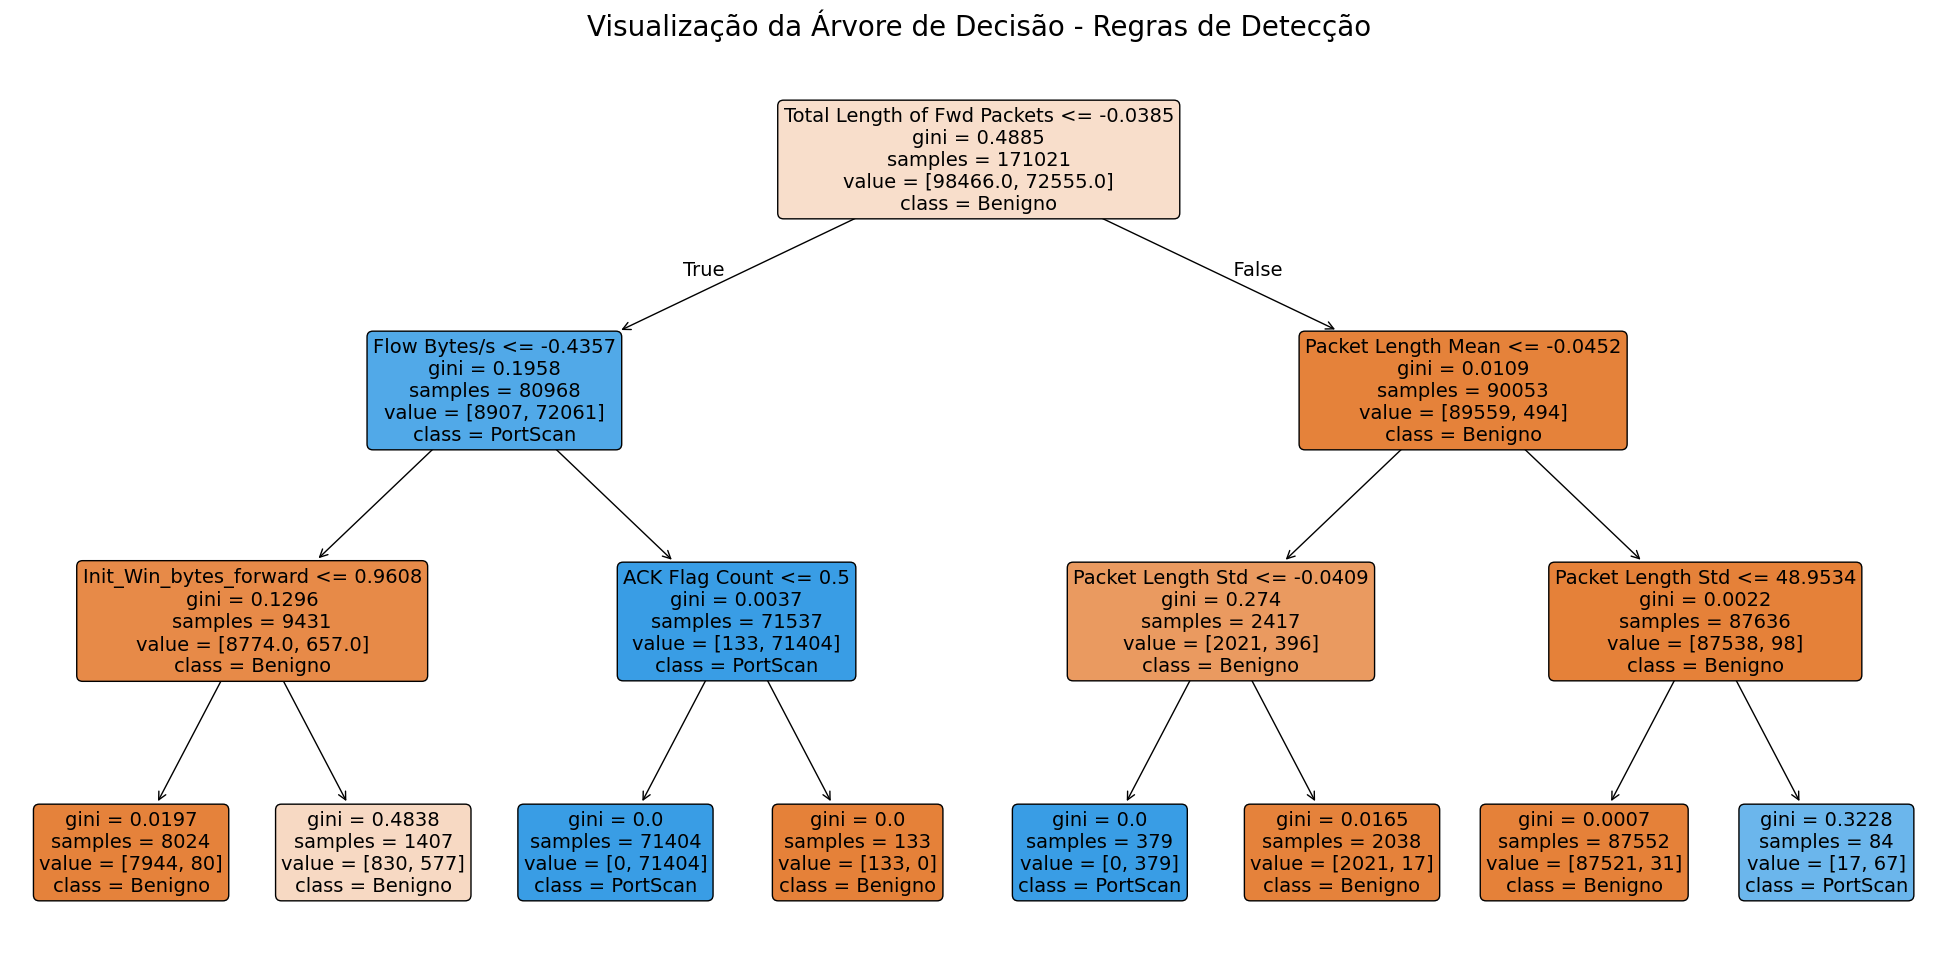

In [122]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Configuramos o tamanho da imagem para ser legível
plt.figure(figsize=(25, 12))

# Plotando a árvore
plot_tree(modelo_tree, 
          feature_names=features_para_escalonar, # Nomes das suas colunas
          class_names=['Benigno', 'PortScan'],   # 0 e 1
          filled=True,                           # Cores para identificar as classes
          rounded=True,                          # Bordas arredondadas
          fontsize=14,                           # Tamanho da letra
          precision=4)                           # Casas decimais nos cálculos

plt.title("Visualização da Árvore de Decisão - Regras de Detecção", fontsize=20)
plt.show()

### Randam Florest


In [123]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Instanciar o modelo
# n_estimators=100 (cria 100 árvores)
# n_jobs=-1 (usa todos os núcleos do seu processador para ser rápido)
modelo_rf = RandomForestClassifier(n_estimators=10, random_state=42, n_jobs=-1)

# 2. Treinar
print("Treinando a Floresta... Isso pode demorar um pouco mais que a árvore simples.")
modelo_rf.fit(X_train_scaled, y_train)

# 3. Predizer
y_pred_rf = modelo_rf.predict(X_test_scaled)

# 4. Resultados
print(f"\nAcurácia Random Forest: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_rf, target_names=['Benigno', 'PortScan']))

Treinando a Floresta... Isso pode demorar um pouco mais que a árvore simples.

Acurácia Random Forest: 0.9999

Relatório de Classificação:
              precision    recall  f1-score   support

     Benigno       1.00      1.00      1.00     24617
    PortScan       1.00      1.00      1.00     18139

    accuracy                           1.00     42756
   macro avg       1.00      1.00      1.00     42756
weighted avg       1.00      1.00      1.00     42756



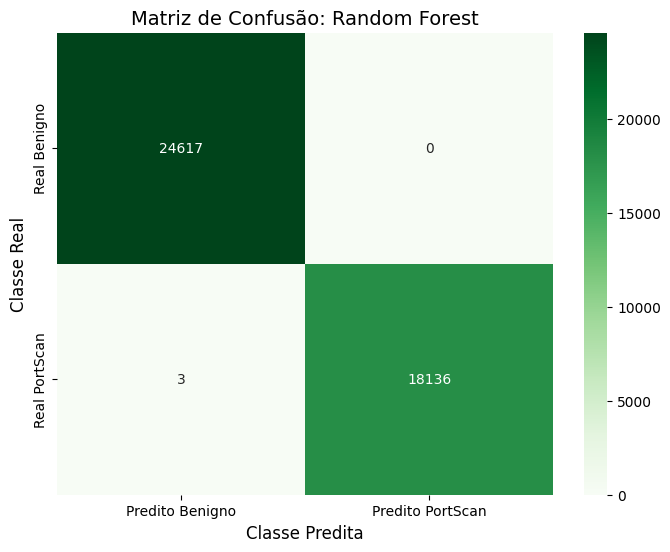

In [124]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Gerar a matriz para o Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

# 2. Plotar o gráfico
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Predito Benigno', 'Predito PortScan'],
            yticklabels=['Real Benigno', 'Real PortScan'])

plt.title('Matriz de Confusão: Random Forest', fontsize=14)
plt.ylabel('Classe Real', fontsize=12)
plt.xlabel('Classe Predita', fontsize=12)
plt.show()

C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_17004\2512197615.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Atributo', data=df_importancia, palette='viridis')


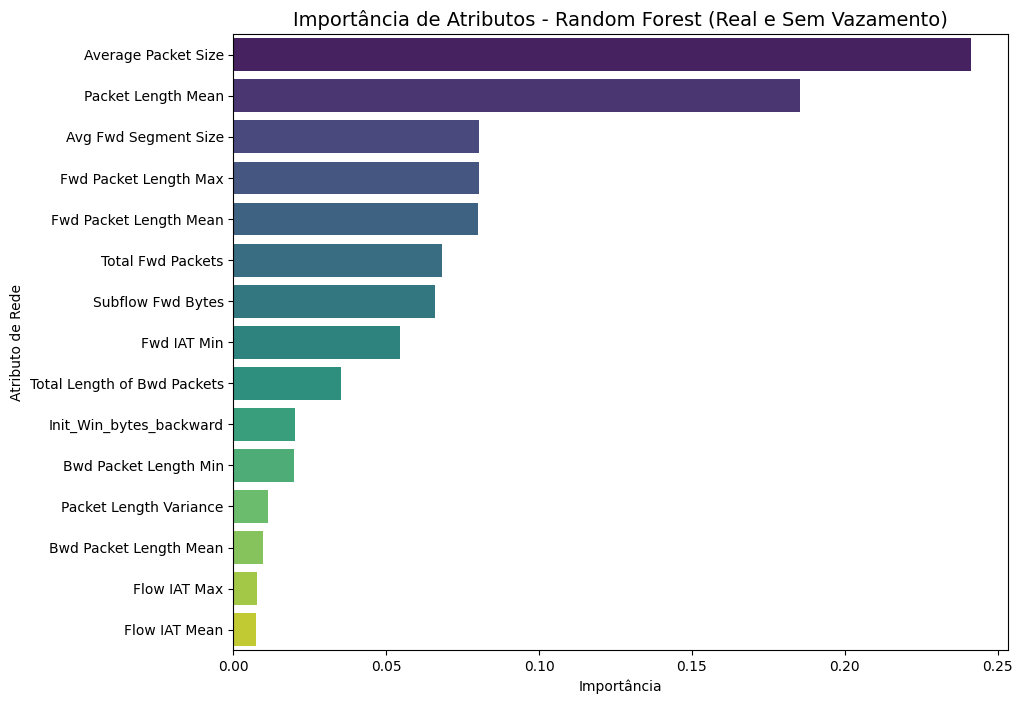

In [126]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pegar as importâncias do modelo
importancias = modelo_rf.feature_importances_

# 2. Pegar os nomes das colunas diretamente do DataFrame X que você usou para treinar
# Isso garante que a ordem e a quantidade de nomes batam 100% com os valores
colunas = X.columns 

# 3. Criar o DataFrame com os tamanhos corretos
df_importancia = pd.DataFrame({'Atributo': colunas, 'Importancia': importancias})
df_importancia = df_importancia.sort_values(by='Importancia', ascending=False).head(15)

# 4. Plotar o gráfico
plt.figure(figsize=(10, 8))
sns.barplot(x='Importancia', y='Atributo', data=df_importancia, palette='viridis')

plt.title('Importância de Atributos - Random Forest (Real e Sem Vazamento)', fontsize=14)
plt.xlabel('Importância')
plt.ylabel('Atributo de Rede')
plt.show()

## XGBoost

In [127]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Instanciar o modelo
# use_label_encoder=False evita avisos de depreciação
modelo_xgb = XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42,
    verbosity=1
)

# 2. Treinar
print("Treinando o XGBoost...")
modelo_xgb.fit(X_train_scaled, y_train)

# 3. Predizer
y_pred_xgb = modelo_xgb.predict(X_test_scaled)

# 4. Avaliar
print("\nMatriz de Confusão XGBoost:")
print(confusion_matrix(y_test, y_pred_xgb))
print("\nRelatório:")
print(classification_report(y_test, y_pred_xgb))

Treinando o XGBoost...

Matriz de Confusão XGBoost:
[[24616     1]
 [    1 18138]]

Relatório:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     24617
           1       1.00      1.00      1.00     18139

    accuracy                           1.00     42756
   macro avg       1.00      1.00      1.00     42756
weighted avg       1.00      1.00      1.00     42756



C:\Users\Guilherme Martins\AppData\Local\Temp\ipykernel_17004\1246454104.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Atributo', data=importancias_xgb, palette='rocket')


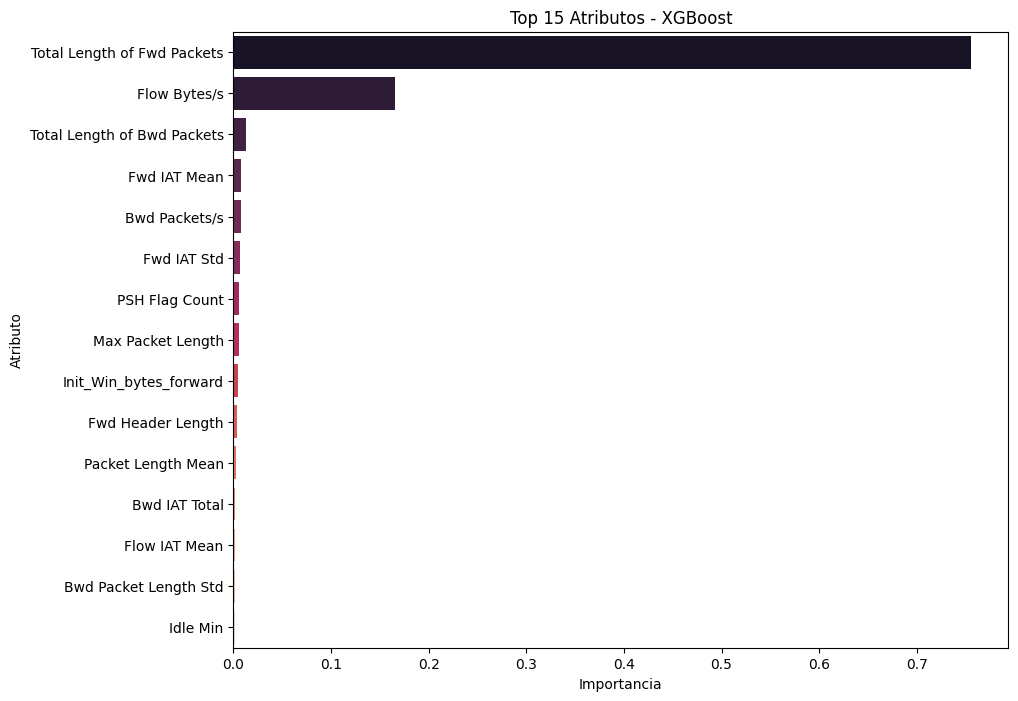

In [129]:
importancias_xgb = pd.DataFrame({
    'Atributo': X.columns,
    'Importancia': modelo_xgb.feature_importances_
}).sort_values(by='Importancia', ascending=False).head(15)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importancia', y='Atributo', data=importancias_xgb, palette='rocket')
plt.title('Top 15 Atributos - XGBoost')
plt.show()